# Lab 2: K-Nearest Neighbors and Radius Neighbors Classification

**Name:** Todd Simonson
**Course:** MSCS-634: Advanced Big Data and Data Mining
**Instructor:** Dr. Satish Penmatsa
**Assignment:** Lab 2: Comparing KNN and Radius Neighbors Classifiers on the Wine Dataset

## Step 1: Load and Prepare the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import pairwise_distances, confusion_matrix, ConfusionMatrixDisplay

pd.set_option('display.width', 160)
RANDOM_STATE = 42

In [2]:
# load the wine dataset as a dataframe so feature names stay attached
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
class_names = [str(n) for n in wine.target_names]

print('samples:', X.shape[0], ' features:', X.shape[1])
print('classes:', class_names)
X.head()

samples: 178  features: 13
classes: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Feature details

In [3]:
# summary statistics for every feature
X.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


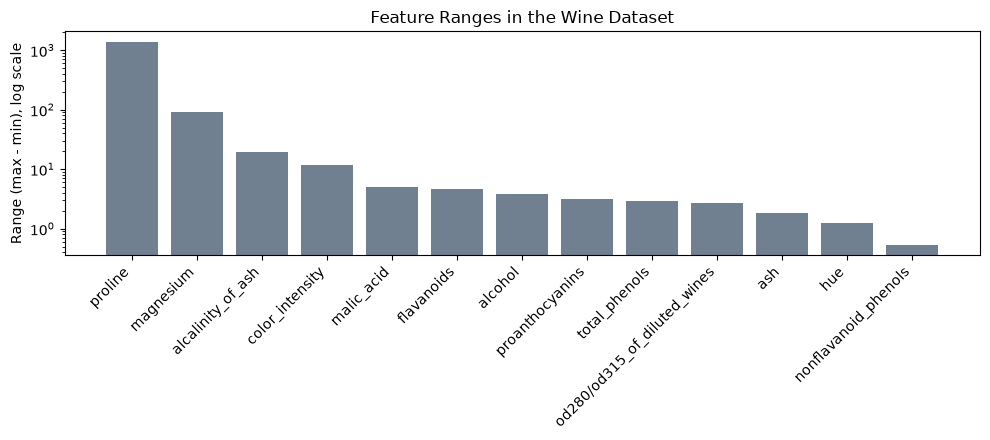

proline range: 1402
next largest range (magnesium): 92
smallest range (nonflavanoid_phenols): 0.53


In [4]:
# features have very different ranges, which matters for any distance-based model
ranges = (X.max() - X.min()).sort_values(ascending=False)

plt.figure(figsize=(10, 4.5))
plt.bar(ranges.index, ranges.values, color='slategray')
plt.yscale('log')
plt.ylabel('Range (max - min), log scale')
plt.title('Feature Ranges in the Wine Dataset')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f"proline range: {ranges['proline']:.0f}")
print(f"next largest range (magnesium): {ranges['magnesium']:.0f}")
print(f"smallest range (nonflavanoid_phenols): {ranges['nonflavanoid_phenols']:.2f}")

**Observation:** The features are measured on very different scales. Proline spans 1,402 units (278 to 1,680), magnesium spans 92, and nonflavanoid phenols span only 0.53. Because KNN and Radius Neighbors measure similarity with Euclidean distance, a feature with a range in the thousands will outweigh features with ranges below 1. The lab specifies radius values of 350 to 600, which only make sense on this unscaled scale, so the required experiments use raw features. A standardized comparison is added afterward.

### Class distribution

class_0    59
class_1    71
class_2    48
Name: count, dtype: int64
class_0    33.1
class_1    39.9
class_2    27.0
Name: count, dtype: float64


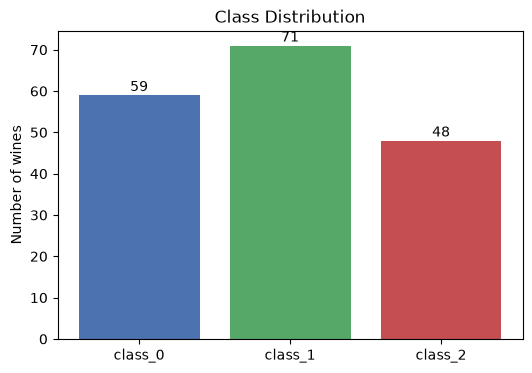

In [5]:
counts = y.value_counts().sort_index()
counts.index = [class_names[i] for i in counts.index]
print(counts)
print((counts / counts.sum() * 100).round(1))

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=['#4C72B0', '#55A868', '#C44E52'])
for i, v in enumerate(counts.values):
    plt.text(i, v + 1, str(v), ha='center')
plt.ylabel('Number of wines')
plt.title('Class Distribution')
plt.show()

**Observation:** The three classes are moderately imbalanced: class_1 has 71 wines (39.9%), class_0 has 59 (33.1%), and class_2 has 48 (27.0%). Always guessing the largest class would score about 39% on the test set, so that is the baseline any useful model must beat. The imbalance is mild enough that accuracy is still a meaningful metric, and stratifying the split keeps the proportions equal in training and testing.

### Train/test split

The data is split 80% for training and 20% for testing. The split is **stratified**, so each class keeps the same share in both sets. A fixed random seed makes every result in this notebook reproducible.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print('training samples:', len(X_train))
print('testing samples: ', len(X_test))
pd.DataFrame({'train': y_train.value_counts().sort_index(),
              'test': y_test.value_counts().sort_index()}).set_axis(class_names)

training samples: 142
testing samples:  36


,train,test
class_0,47,12
class_1,57,14
class_2,38,10


## Step 2: K-Nearest Neighbors (KNN)

KNN classifies a test wine by finding the *k* closest training wines (Euclidean distance) and taking a majority vote of their classes. Models are trained on the raw, unscaled features as specified in the lab.

In [7]:
k_values = [1, 5, 11, 15, 21]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = knn.score(X_test, y_test)
    knn_results.append({'k': k, 'accuracy': acc, 'correct': int(round(acc * len(y_test)))})

knn_df = pd.DataFrame(knn_results)
knn_df['accuracy_pct'] = (knn_df['accuracy'] * 100).round(2)
knn_df

,k,accuracy,correct,accuracy_pct
0,1,0.777778,28,77.78
1,5,0.805556,29,80.56
2,11,0.805556,29,80.56
3,15,0.805556,29,80.56
4,21,0.805556,29,80.56


## Step 3: Radius Neighbors (RNN)

Radius Neighbors classifies a test wine by a majority vote of **every** training wine within a fixed distance (the radius), so the number of voters changes from one test point to the next. If a test point has no training wines inside its radius, the classifier has no neighbors to vote with. `outlier_label='most_frequent'` tells it to fall back to the most common training class in that case, rather than raising an error. The cell below also counts how many neighbors each test point actually used.

In [8]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_results = []

# distance from every test wine to every training wine, used to count neighbors inside each radius
dist = pairwise_distances(X_test, X_train)

for r in radius_values:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent')
    rnn.fit(X_train, y_train)
    acc = rnn.score(X_test, y_test)
    n_neighbors = (dist <= r).sum(axis=1)
    rnn_results.append({'radius': r, 'accuracy': acc,
                        'correct': int(round(acc * len(y_test))),
                        'mean_neighbors': n_neighbors.mean(),
                        'min_neighbors': n_neighbors.min(),
                        'pct_of_training_set': n_neighbors.mean() / len(X_train) * 100,
                        'test_points_with_no_neighbors': int((n_neighbors == 0).sum())})

rnn_df = pd.DataFrame(rnn_results)
rnn_df['accuracy_pct'] = (rnn_df['accuracy'] * 100).round(2)
rnn_df.round(2)

,radius,accuracy,correct,mean_neighbors,min_neighbors,pct_of_training_set,test_points_with_no_neighbors,accuracy_pct
0,350,0.72,26,80.53,4,56.71,0,72.22
1,400,0.69,25,87.86,9,61.87,0,69.44
2,450,0.69,25,94.83,14,66.78,0,69.44
3,500,0.69,25,100.06,17,70.46,0,69.44
4,550,0.67,24,105.97,19,74.63,0,66.67
5,600,0.67,24,110.97,23,78.15,0,66.67


## Step 4: Visualize and Compare Results

### Accuracy trend for KNN

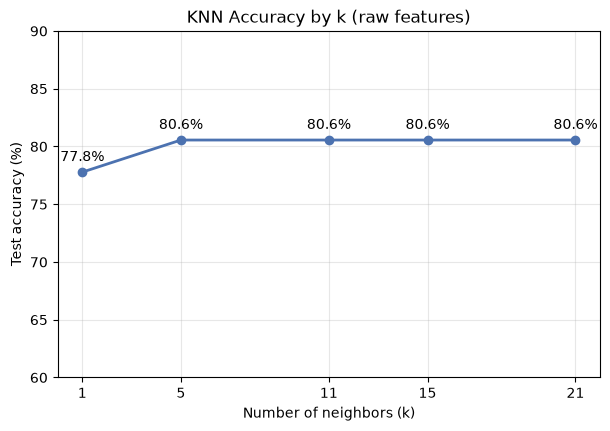

In [9]:
plt.figure(figsize=(7, 4.5))
plt.plot(knn_df['k'], knn_df['accuracy_pct'], marker='o', linewidth=2, color='#4C72B0')
for k, a in zip(knn_df['k'], knn_df['accuracy_pct']):
    plt.annotate(f'{a:.1f}%', (k, a), textcoords='offset points', xytext=(0, 8), ha='center')
plt.xticks(k_values)
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Test accuracy (%)')
plt.title('KNN Accuracy by k (raw features)')
plt.ylim(60, 90)
plt.grid(alpha=0.3)
plt.show()

**Observation:** KNN accuracy rises from 77.78% at k = 1 to 80.56% at k = 5 and then stays flat through k = 21. Because the test set has 36 wines, the whole difference is one additional wine classified correctly (28 vs. 29). With k = 1, a single nearest neighbor decides each prediction, so one atypical training wine can cause an error. Averaging over 5 or more neighbors smooths that out. The plateau means that once k reaches 5, adding more neighbors does not change any prediction on this test set.

### Accuracy trend for Radius Neighbors

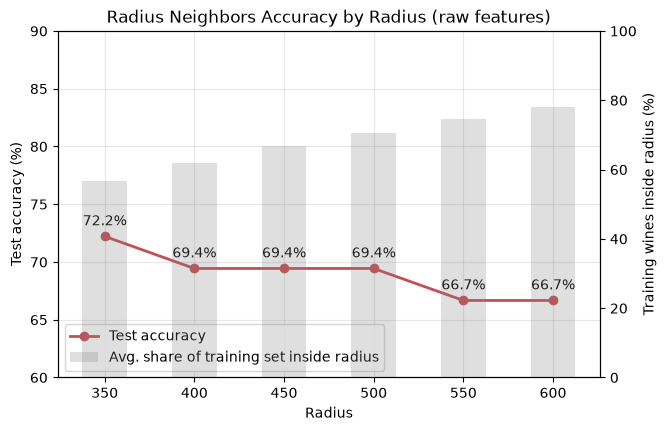

In [10]:
fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax1.plot(rnn_df['radius'], rnn_df['accuracy_pct'], marker='o', linewidth=2, color='#C44E52', label='Test accuracy')
for r, a in zip(rnn_df['radius'], rnn_df['accuracy_pct']):
    ax1.annotate(f'{a:.1f}%', (r, a), textcoords='offset points', xytext=(0, 8), ha='center')
ax1.set_xlabel('Radius')
ax1.set_ylabel('Test accuracy (%)')
ax1.set_ylim(60, 90)
ax1.set_xticks(radius_values)

# second axis: how much of the training set falls inside the radius on average
ax2 = ax1.twinx()
ax2.bar(rnn_df['radius'], rnn_df['pct_of_training_set'], width=25, alpha=0.25, color='gray',
        label='Avg. share of training set inside radius')
ax2.set_ylabel('Training wines inside radius (%)')
ax2.set_ylim(0, 100)

lines = ax1.get_legend_handles_labels()
bars = ax2.get_legend_handles_labels()
ax1.legend(lines[0] + bars[0], lines[1] + bars[1], loc='lower left')
ax1.set_title('Radius Neighbors Accuracy by Radius (raw features)')
ax1.grid(alpha=0.3)
plt.show()

**Observation:** Radius Neighbors accuracy falls as the radius grows: 72.22% at a radius of 350, 69.44% from 400 to 500, and 66.67% at 550 and 600. The gray bars explain why. At a radius of 350, each test wine already has about 81 training wines inside its radius (57% of the training set); at 600 it has about 111 (78%). As the radius widens, the vote pulls in wines that are not similar at all, and the prediction drifts toward whichever class is most common in the training set. Every test wine had at least 4 neighbors at every radius, so the outlier fallback was never used.

### Why the results look this way: one feature controls the distance

Both models rely on Euclidean distance, which adds up squared differences across all 13 features. On raw data, a feature with a large range dominates that sum. The cell below measures how much of the squared distance between test and training wines comes from proline alone.

In [11]:
# share of the total squared distance contributed by each feature
diff_sq = (X_test.values[:, None, :] - X_train.values[None, :, :]) ** 2
share = pd.Series(diff_sq.sum(axis=(0, 1)) / diff_sq.sum(), index=X.columns).sort_values(ascending=False)
(share * 100).round(2).head(5)

proline              99.82
magnesium             0.16
alcalinity_of_ash     0.01
color_intensity       0.00
malic_acid            0.00
dtype: float64

**Observation:** Proline contributes **99.82%** of the total squared distance between test and training wines, and magnesium contributes most of the rest (0.16%). On raw features, both models are effectively classifying wines by proline alone and ignoring the other 12 chemical measurements.

In [12]:
# proline by class shows which classes the dominant feature can and cannot separate
X.assign(wine_class=y.map(dict(enumerate(class_names)))).groupby('wine_class')['proline'].describe()[['mean', 'min', '25%', '50%', '75%', 'max']].round(0)

,mean,min,25%,50%,75%,max
wine_class,,,,,,
class_0,1116.0,680.0,988.0,1095.0,1280.0,1680.0
class_1,520.0,278.0,406.0,495.0,625.0,985.0
class_2,630.0,415.0,545.0,628.0,695.0,880.0


**Observation:** Proline separates class_0 cleanly. Its median is 1,095, and even its 25th percentile (988) is higher than the largest proline value in class_1 (985) or class_2 (880). Class_1 (median 495) and class_2 (median 628) overlap heavily, however: their middle 50% ranges are 406 to 625 and 545 to 695. A model that relies almost entirely on proline should classify class_0 well and confuse class_1 with class_2, which is exactly what the confusion matrices below show.

### Supplementary check 1: the same models on standardized features

To test that explanation, both models are retrained after standardizing each feature to mean 0 and standard deviation 1. The scaler is fit on the training set only, so no information from the test set leaks into training. On standardized data, the lab's radius values (350 to 600) would include every training wine for every test point, so a radius range matched to the standardized distances is used instead. The median distance between a test wine and a training wine is printed for reference.

In [13]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

dist_s = pairwise_distances(X_test_s, X_train_s)
print(f'median test-to-train distance, raw features:          {np.median(dist):.1f}')
print(f'median test-to-train distance, standardized features: {np.median(dist_s):.2f}')

scaled_knn = pd.DataFrame({'k': k_values,
                           'raw_accuracy_pct': knn_df['accuracy_pct'],
                           'scaled_accuracy_pct': [round(KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
                                                         .score(X_test_s, y_test) * 100, 2) for k in k_values]})

scaled_radii = [2.0, 2.5, 3.0, 3.5, 4.0, 5.0]
scaled_rnn = pd.DataFrame({'radius': scaled_radii,
                           'scaled_accuracy_pct': [round(RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent')
                                                         .fit(X_train_s, y_train).score(X_test_s, y_test) * 100, 2)
                                                   for r in scaled_radii],
                           'mean_neighbors': [(dist_s <= r).sum(axis=1).mean().round(1) for r in scaled_radii],
                           'test_points_with_no_neighbors': [int(((dist_s <= r).sum(axis=1) == 0).sum()) for r in scaled_radii]})
display(scaled_knn)
display(scaled_rnn)

median test-to-train distance, raw features:          288.2
median test-to-train distance, standardized features: 5.13


,k,raw_accuracy_pct,scaled_accuracy_pct
0,1,77.78,97.22
1,5,80.56,97.22
2,11,80.56,100.00
3,15,80.56,100.00
4,21,80.56,100.00


,radius,scaled_accuracy_pct,mean_neighbors,test_points_with_no_neighbors
0,2.0,86.11,1.5,16
1,2.5,97.22,6.6,2
2,3.0,97.22,15.2,1
3,3.5,100.00,26.2,1
4,4.0,94.44,38.7,0
5,5.0,86.11,66.2,0


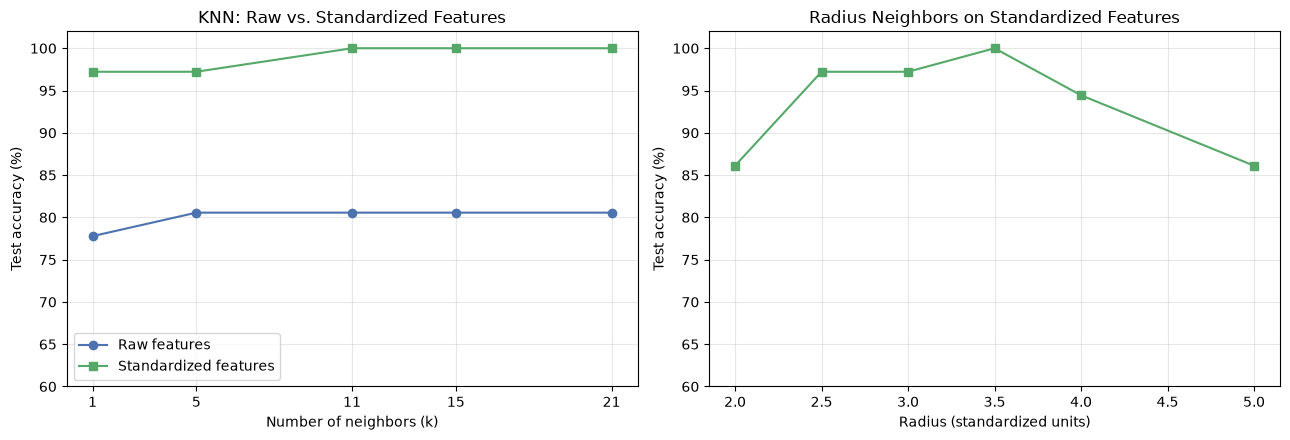

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, scaled_knn['raw_accuracy_pct'], marker='o', label='Raw features', color='#4C72B0')
axes[0].plot(k_values, scaled_knn['scaled_accuracy_pct'], marker='s', label='Standardized features', color='#55A868')
axes[0].set_xticks(k_values)
axes[0].set_xlabel('Number of neighbors (k)')
axes[0].set_ylabel('Test accuracy (%)')
axes[0].set_title('KNN: Raw vs. Standardized Features')
axes[0].set_ylim(60, 102)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(scaled_rnn['radius'], scaled_rnn['scaled_accuracy_pct'], marker='s', color='#55A868')
axes[1].set_xlabel('Radius (standardized units)')
axes[1].set_ylabel('Test accuracy (%)')
axes[1].set_title('Radius Neighbors on Standardized Features')
axes[1].set_ylim(60, 102)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation:** Standardizing the features confirms the explanation. KNN accuracy jumps from 77.78% to 80.56% on raw features to 97.22% to 100% on standardized features, at every value of k. Radius Neighbors on standardized data reaches 100% at a radius of 3.5. Its curve rises and then falls, which shows the trade-off in choosing a radius. At 2.0 the radius is too small: 16 of 36 test wines have no neighbors and fall back to the most frequent class. At 5.0 it is too large: the radius covers about 66 neighbors and accuracy drops back to 86.11%. The lab's radius range of 350 to 600 sits entirely on the "too large" side of that trade-off for raw data.

### Supplementary check 2: are the differences real or test-set noise?

The test set has only 36 wines, so a single misclassification moves accuracy by 2.78 percentage points. To see whether the trends hold beyond this one split, each configuration is also evaluated with stratified 5-fold cross-validation on the training set.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for k in k_values:
    s = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=cv)
    cv_rows.append({'model': 'KNN', 'parameter': f'k = {k}', 'cv_mean_pct': s.mean() * 100, 'cv_std_pct': s.std() * 100})
for r in radius_values:
    s = cross_val_score(RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent'), X_train, y_train, cv=cv)
    cv_rows.append({'model': 'RNN', 'parameter': f'radius = {r}', 'cv_mean_pct': s.mean() * 100, 'cv_std_pct': s.std() * 100})

cv_df = pd.DataFrame(cv_rows).round(2)
cv_df

,model,parameter,cv_mean_pct,cv_std_pct
0,KNN,k = 1,75.42,6.78
1,KNN,k = 5,70.47,3.86
2,KNN,k = 11,70.44,4.64
3,KNN,k = 15,71.13,4.08
4,KNN,k = 21,70.42,6.16
5,RNN,radius = 350,66.23,3.20
6,RNN,radius = 400,64.80,4.90
7,RNN,radius = 450,64.80,4.90
8,RNN,radius = 500,64.78,4.52
9,RNN,radius = 550,64.80,2.94


**Observation:** Cross-validation tells a more cautious story than the single test split. KNN averages 70.4% to 75.4% across folds, below the 80.56% test score, and k = 1 scores highest (75.42%), the reverse of the test-set result. Fold-to-fold variation of 3.9 to 6.8 points is larger than the gaps between k values, so the evidence does not support one k over another on raw data. Two conclusions do hold on both evaluations: KNN beats Radius Neighbors at every setting (about 70% to 75% vs. 64% to 66% in cross-validation), and Radius Neighbors gets slightly worse as the radius grows.

### Where the best raw models make mistakes

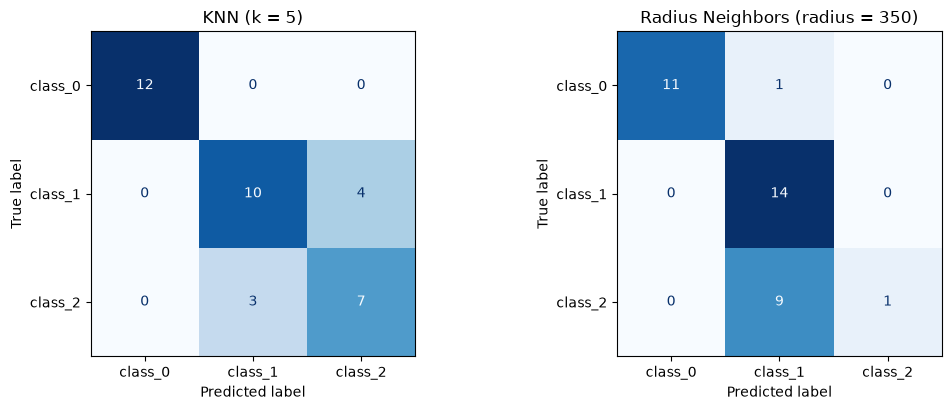

In [16]:
best_k = int(knn_df.loc[knn_df['accuracy'].idxmax(), 'k'])
best_r = int(rnn_df.loc[rnn_df['accuracy'].idxmax(), 'radius'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, model, title in zip(axes,
                            [KNeighborsClassifier(n_neighbors=best_k), RadiusNeighborsClassifier(radius=best_r, outlier_label='most_frequent')],
                            [f'KNN (k = {best_k})', f'Radius Neighbors (radius = {best_r})']):
    pred = model.fit(X_train, y_train).predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Observation:** Both models classify every class_0 wine correctly, which matches its high proline values. The models differ on the overlapping classes. KNN (k = 5) makes 7 errors, split between class_1 and class_2 in both directions (4 and 3). Radius Neighbors (radius = 350) makes 10 errors, and 9 of them are class_2 wines labeled as class_1. With about 80 training wines voting on each prediction, the larger class_1 (57 training wines vs. 38 for class_2) outvotes class_2 almost every time. KNN avoids this because it limits the vote to the 5 closest wines.

## Comparison and Discussion

### How the two models compared

| | KNN (raw) | Radius Neighbors (raw) |
|---|---|---|
| Best test accuracy | 80.56% (k = 5 to 21) | 72.22% (radius = 350) |
| Worst test accuracy | 77.78% (k = 1) | 66.67% (radius = 550, 600) |
| Cross-validation range | 70.4% to 75.4% | 64.1% to 66.2% |
| Trend | Flat after k = 5 | Declines as radius grows |
| Main error | Class_1 and class_2 confused in both directions | Class_2 absorbed into class_1 |

KNN outperformed Radius Neighbors at every parameter value tested, on both the test set and in cross-validation. The difference comes from how each model chooses its voters. KNN always uses a fixed, small number of the closest wines, so the vote stays local. With the lab's radius values on raw data, Radius Neighbors included 57% to 78% of the entire training set in every vote. That is no longer a nearest-neighbor method in any meaningful sense, and it is biased toward the majority class.

The most important observation is that neither parameter mattered as much as feature scaling. Proline alone accounted for 99.82% of the distance calculation, so on raw data both models were close to one-feature classifiers. After standardization, KNN reached 97% to 100% accuracy at every k and Radius Neighbors reached 100% at a radius of 3.5. Those results come from a single 36-wine test set and should be read as a strong improvement, not as proof of perfect accuracy.

### When KNN or Radius Neighbors is preferable

**KNN is preferable when:**
* Data density varies across the feature space. KNN always finds k neighbors, whether a point is in a dense region or a sparse one.
* Feature scales are uncertain or not yet tuned. KNN's performance was stable across every k tested here, while Radius Neighbors swung widely depending on whether the radius suited the scale of the data.
* Classes are imbalanced. A small k keeps the majority class from dominating, as the class_2 errors from Radius Neighbors showed.

**Radius Neighbors is preferable when:**
* Distance itself has a real-world meaning, such as geographic or sensor data, where "everything within 5 km" is a natural rule and a fixed number of neighbors is not.
* Data is evenly dense, so a single radius gives each point a sensible number of neighbors.
* Detecting unusual points matters. A point with no neighbors inside the radius is a signal that it is unlike the training data, which KNN never reveals because it always finds k neighbors. On standardized data, the radius of 2.0 left 16 test wines with no neighbors, showing how this works.

**For this dataset,** KNN on standardized features is the better choice. It was accurate at every k tested and does not require tuning a radius to the scale of the data.